<a href="https://colab.research.google.com/github/VielF/ColabProjects/blob/main/Pr%C3%A1tica_Processamento_Morfol%C3%B3gico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Universidade do Vale do Itajaí<br>
Escola Politécnica<br>
Processamento Digital de Sinais: Imagens

# Exercício Avalitivo de Processamento Morfológico

### Tutoriais da OpenCV

- https://docs.opencv.org/master/d9/df8/tutorial_root.html
- https://www.geeksforgeeks.org/opencv-python-tutorial/

## Processamento Morfológico
#### Obs: Utilize imagens em preto e branco.


### Erosão e Dilatação

1. Implemente a sua própria versão da erosão em formato de função, com capacidade de trabalhar com diferentes elementos estruturantes (tamanho e forma) e aplique o algoritmos na na figura ImagensMorfologia/Fig0905(a)(wirebond-mask)
2. Implemente a sua própria versão da dilatação em formato de função, com capacidade de trabalhar com diferentes elementos estruturantes (tamanho e forma) e aplique o algoritmos na na figura ImagensMorfologia/Fig0907(a)(text_gaps_1_and_2_pixels) 
4. Relate as observações visíveis nas imagens de saída com os processamentos aplicados, descrevendo o comportamento visual em relação as bordas, junção, perda de informação e mlhoria na qualidade visual.
5. Aplique o seu algoritmo de detecção de borda (roberts ou sobel) a imagem ImagensMorfologia/Fig0905(a)(wirebond-mask) antes e depois de utilizar a dilatação/erosão e relate os resultados.

#### Dicas
 - Você pode adicionar ruído nas imagens usando a função random_noise: `from skimage.util import random_noise`. Cuidado com o retorno da função, talvez seja necessário regularizar a mesma novamente para o intervalo de 0 à 255. O ruído pode ser intensificado ou excluído com processamento morfológico.

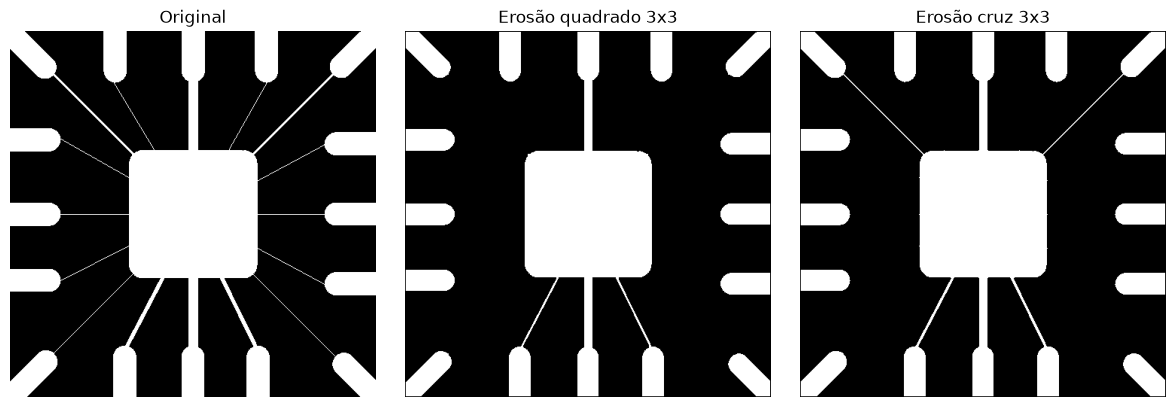

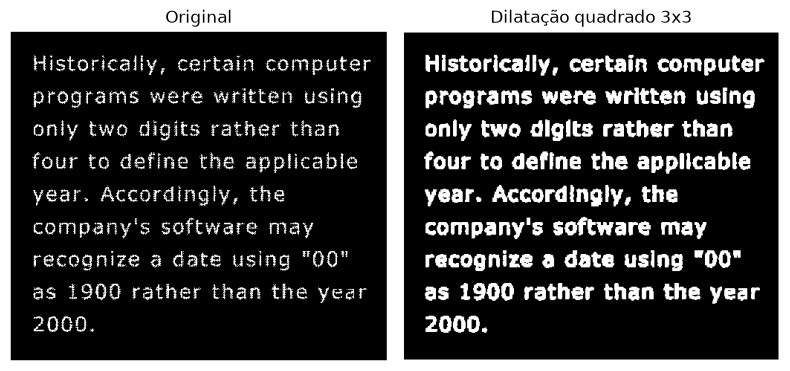

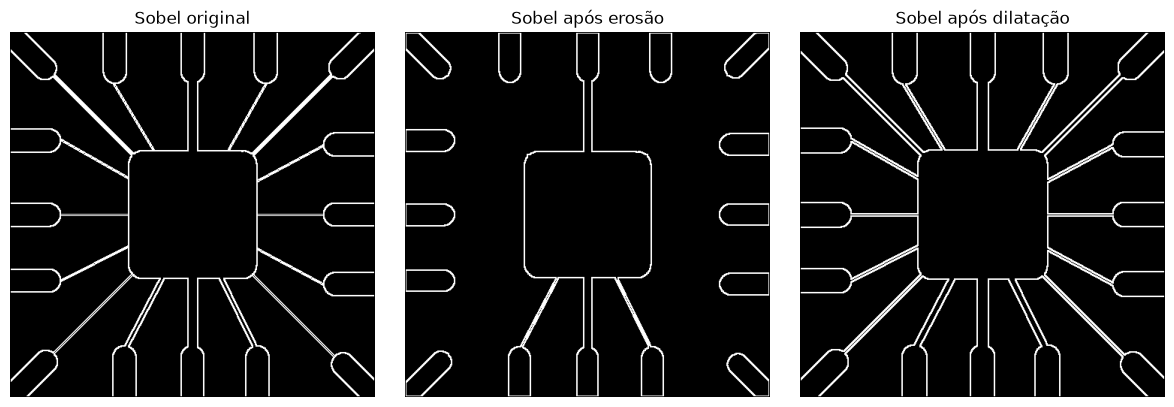

In [8]:
import math
from PIL import Image

import matplotlib.pyplot as plt
import numpy as np


def carregar(caminho):
    imagem = Image.open(caminho).convert("L")
    return np.array(imagem, dtype=np.uint8)


def erosao(imagem, elemento):
    altura, largura = imagem.shape
    eh = len(elemento)
    ew = len(elemento[0])
    oy = eh // 2
    ox = ew // 2
    saida = np.zeros((altura, largura), dtype=np.uint8)
    for y in range(altura):
        for x in range(largura):
            cabe = True
            for i in range(eh):
                yy = y + i - oy
                for j in range(ew):
                    if elemento[i][j] == 0:
                        continue
                    xx = x + j - ox
                    if yy < 0 or xx < 0 or yy >= altura or xx >= largura or imagem[yy, xx] == 0:
                        cabe = False
                        break
                if not cabe:
                    break
            if cabe:
                saida[y, x] = 255
    return saida


def dilatacao(imagem, elemento):
    altura, largura = imagem.shape
    eh = len(elemento)
    ew = len(elemento[0])
    oy = eh // 2
    ox = ew // 2
    saida = np.zeros((altura, largura), dtype=np.uint8)
    for y in range(altura):
        for x in range(largura):
            acertou = False
            for i in range(eh):
                yy = y + i - oy
                for j in range(ew):
                    if elemento[i][j] == 0:
                        continue
                    xx = x + j - ox
                    if 0 <= yy < altura and 0 <= xx < largura and imagem[yy, xx] > 0:
                        acertou = True
                        break
                if acertou:
                    break
            if acertou:
                saida[y, x] = 255
    return saida


def abertura(imagem, elemento):
    return dilatacao(erosao(imagem, elemento), elemento)


def fechamento(imagem, elemento):
    return erosao(dilatacao(imagem, elemento), elemento)


def sobel(imagem):
    gx_k = ((-1, 0, 1), (-2, 0, 2), (-1, 0, 1))
    gy_k = ((-1, -2, -1), (0, 0, 0), (1, 2, 1))
    altura, largura = imagem.shape
    saida = np.zeros((altura, largura), dtype=np.uint8)
    for y in range(1, altura - 1):
        for x in range(1, largura - 1):
            gx = 0
            gy = 0
            for i in range(3):
                for j in range(3):
                    pixel = int(imagem[y + i - 1, x + j - 1])
                    gx += gx_k[i][j] * pixel
                    gy += gy_k[i][j] * pixel
            magnitude = math.sqrt(gx * gx + gy * gy)
            if magnitude > 255:
                magnitude = 255
            saida[y, x] = int(magnitude)
    return saida


def mostrar(imagens, titulos):
    n = len(imagens)
    fig, eixos = plt.subplots(1, n, figsize=(4 * n, 4))
    if n == 1:
        eixos = [eixos]
    for eixo, imagem, titulo in zip(eixos, imagens, titulos):
        eixo.imshow(imagem, cmap="gray", vmin=0, vmax=255)
        eixo.set_title(titulo)
        eixo.axis("off")
    plt.tight_layout()
    plt.show()


quadrado = [
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1],
]
cruz = [
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0],
]

wirebond = carregar("ImagensMorfologia/Fig0905(a)(wirebond-mask).tif")
erosao_quadrado = erosao(wirebond, quadrado)
erosao_cruz = erosao(wirebond, cruz)
dilatacao_wirebond = dilatacao(wirebond, quadrado)

mostrar(
    [wirebond, erosao_quadrado, erosao_cruz],
    ["Original", "Erosão quadrado 3x3", "Erosão cruz 3x3"],
)

texto = carregar("ImagensMorfologia/Fig0907(a)(text_gaps_1_and_2_pixels).tif")
dilatacao_texto = dilatacao(texto, quadrado)
mostrar(
    [texto, dilatacao_texto],
    ["Original", "Dilatação quadrado 3x3"],
)

mostrar(
    [sobel(wirebond), sobel(erosao_quadrado), sobel(dilatacao_wirebond)],
    ["Sobel original", "Sobel após erosão", "Sobel após dilatação"],
)


Na wirebond, a erosão com quadrado 3×3 recua a borda e apaga os fios de um pixel, na horizontal, na vertical e na diagonal. Sobram os pads e os traços grossos, com perda do detalhe fino. A cruz 3×3 tem o mesmo tamanho e outra forma: apaga os fios diagonais e ainda preserva parte dos fios horizontais e verticais. No texto, a dilatação com quadrado 3×3 engrossa as letras, fecha as falhas de 1 e 2 pixels e junta caracteres vizinhos. A continuidade do traço melhora e a separação entre as letras piora.

O Sobel na imagem original marca o contorno dos pads e dos fios finos. Depois da erosão quadrada, as bordas desses fios somem junto com eles. Depois da dilatação, o contorno segue o traço mais grosso, e ligações que estavam separadas passam a formar uma borda só.


### Abertura e Fechamento

5. Implemente a sua versão do algoritmo de abertura em forma de função com capacidade de trabalhar com diferentes elementos estruturantes (tamanho e forma)
6. Implemente a sua versão do algoritmo de fechamento em forma de função com capacidade de trabalhar com diferentes elementos estruturantes (tamanho e forma)
7. Aplique o processamento indicado na image abaixo usando a figura ImagensMorfologia/Fig0911(a)(noisy_fingerprint)

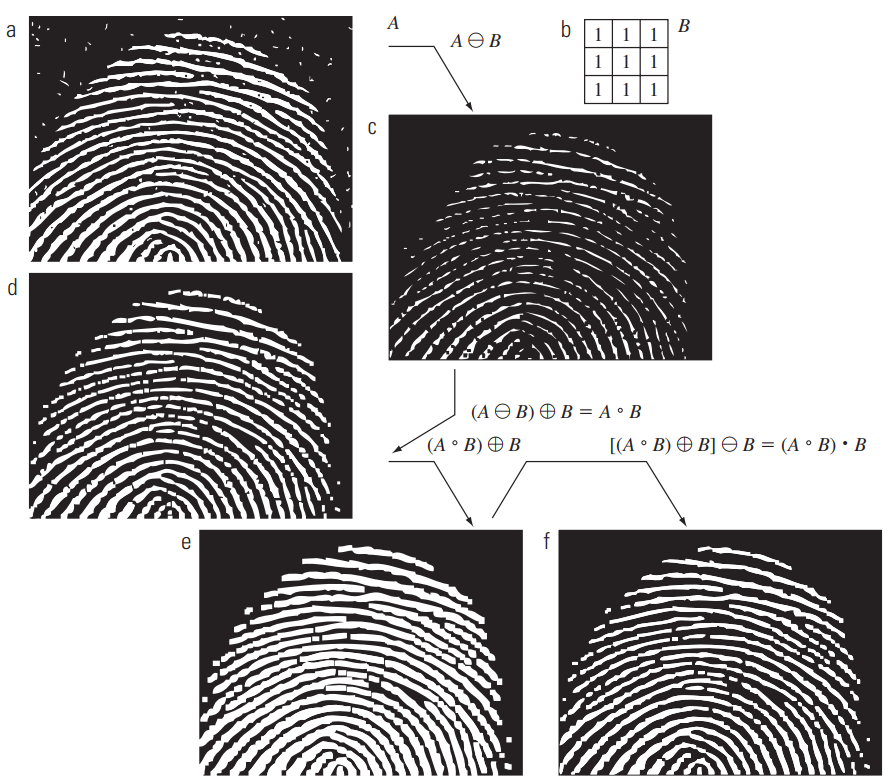

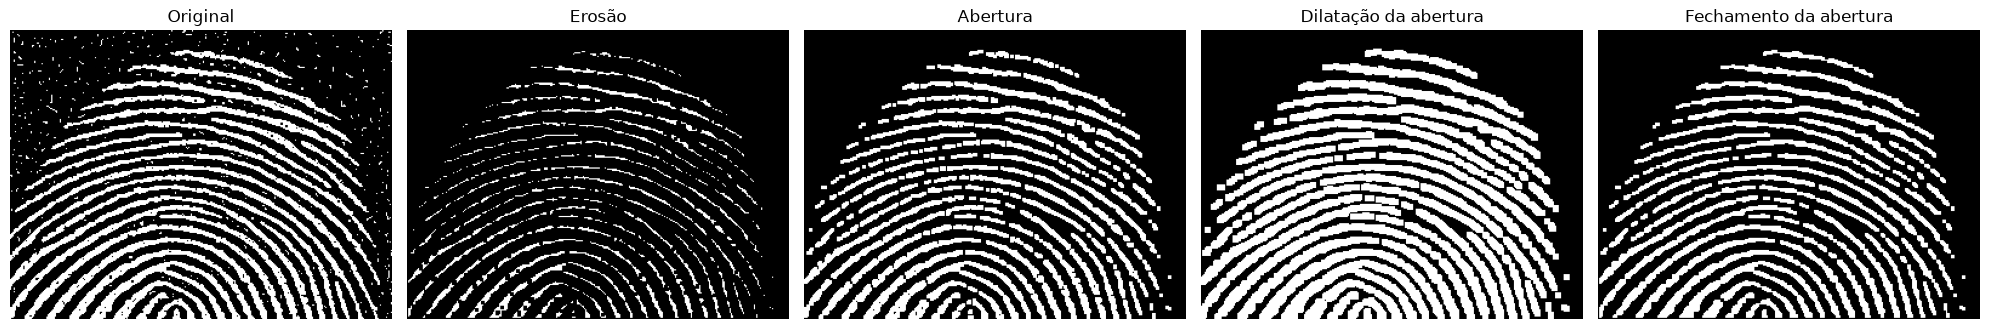

In [9]:
digital = carregar("ImagensMorfologia/Fig0911(a)(noisy_fingerprint).tif")
B = quadrado

erosao_digital = erosao(digital, B)
abertura_digital = abertura(digital, B)
dilatacao_abertura = dilatacao(abertura_digital, B)
fechamento_abertura = fechamento(abertura_digital, B)

mostrar(
    [digital, erosao_digital, abertura_digital, dilatacao_abertura, fechamento_abertura],
    ["Original", "Erosão", "Abertura", "Dilatação da abertura", "Fechamento da abertura"],
)


Na impressão digital, a erosão com o quadrado 3×3 apaga o ruído pontual e também afina e interrompe as cristas. A abertura devolve a espessura das cristas que restaram, sem trazer o ruído de volta, mas as interrupções continuam. A dilatação seguinte engrossa as cristas e junta falhas pequenas, a ponto de algumas se encostarem. O fechamento dessa etapa preenche buracos pequenos e deixa as cristas mais contínuas, com espessura parecida com a da abertura.


## Parte 2 - Filtro Gaussiano na Frequência

Aplicação do filtro Gaussiano passa-baixa na imagem de texto com falhas de 1 e
2 pixels. O código foi adaptado da função `createPB`, no caso `lpType=2`, e da
filtragem com DFT do professor em `refs/Respostas Filtragem na Frequência.ipynb`.

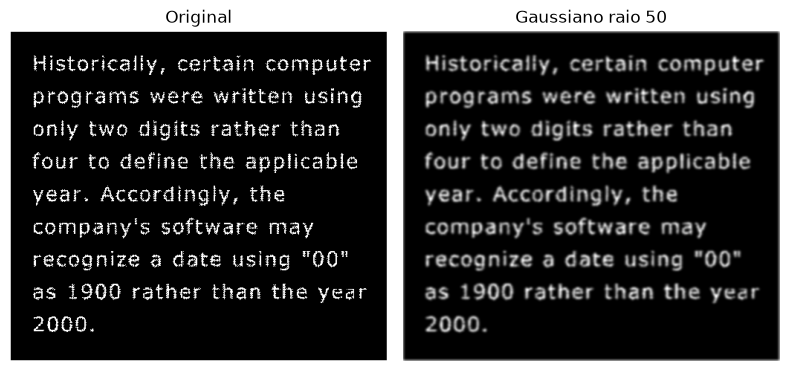

In [ ]:
import cv2


# Caso Gaussiano da função createPB.
def createPB(shape, center, radius):
    rows, cols = shape[:2]
    r, c = np.mgrid[0:rows:1, 0:cols:1]
    c -= center[0]
    r -= center[1]
    d = np.power(c, 2.0) + np.power(r, 2.0)
    lpFilter = np.exp(-d / (2 * pow(radius, 2.0)))
    lpFilter_matrix = np.zeros(shape, np.float32)
    lpFilter_matrix[:, :, 0] = lpFilter
    lpFilter_matrix[:, :, 1] = lpFilter
    return lpFilter_matrix


def gaussiano_frequencia(imagem, raio):
    image_f32 = np.float32(imagem)
    dft = cv2.dft(image_f32, flags=cv2.DFT_COMPLEX_OUTPUT)
    dft_shift = np.fft.fftshift(dft, axes=(0, 1))

    rows, cols = imagem.shape
    maskPB = createPB(dft_shift.shape, center=(cols // 2, rows // 2), radius=raio)
    filtered_freq = dft_shift * maskPB
    f_ishift = np.fft.ifftshift(filtered_freq, axes=(0, 1))
    img_back = cv2.idft(f_ishift)
    img_back = cv2.magnitude(img_back[:, :, 0], img_back[:, :, 1])

    # Normalização para 0 a 255, como no código do professor.
    filtered_img = np.abs(img_back)
    filtered_img -= filtered_img.min()
    if filtered_img.max() > 0:
        filtered_img = filtered_img * 255 / filtered_img.max()
    return filtered_img.astype(np.uint8)


texto_gaussiano = gaussiano_frequencia(texto, raio=50)
mostrar(
    [texto, dilatacao_texto, texto_gaussiano],
    ["Original", "Dilatação quadrado 3x3", "Gaussiano raio 50"],
)

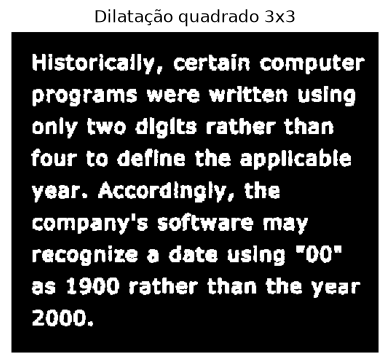

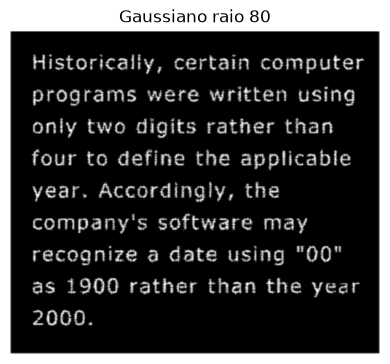

In [11]:
def mostrar_separadas(imagens, titulos):
    for imagem, titulo in zip(imagens, titulos):
        mostrar([imagem], [titulo])


mostrar_separadas(
    [dilatacao_texto, texto_gaussiano],
    ["Dilatação quadrado 3x3", "Gaussiano raio 80"],
)


## Processamento Morfológico vs. Filtro Gaussiano (Domínio da Frequência)

Ao analisar a reconstrução do texto corrompido, nota-se uma diferença acentuada na forma como cada método trata as falhas. O Filtro Gaussiano atua como um filtro passa-baixo, atenuando as altas frequências. Isto provoca um esbatimento (borrão) na imagem, fazendo com que as falhas nos caracteres se unam devido ao espalhamento da intensidade dos píxeis vizinhos. No entanto, o custo desta operação é a perda drástica de nitidez nas bordas das letras.

Por outro lado, o Processamento Morfológico (através de operações como a Dilatação ou o Fechamento) atua diretamente sobre a estrutura espacial dos objetos. A operação expande as regiões dos caracteres, preenchendo os espaços vazios e ligando as quebras com muito mais rigor geométrico. Conclui-se que o método morfológico entrega um resultado superior, garantindo melhor legibilidade, reconstrução estrutural mais fiel e bordas mais definidas face ao esbatimento provocado pelo filtro na frequência.